# Finding the Hidden Pulse

## Mathematical Detection of Natural Video Cut Points in Music

*Math Concepts for Developers — Final Project*

## 1. Introduction

As a creator of music videos, my work often requires choosing cut points that feel natural with the rhythm and structure of the music.

In music with strong transients, such as pronounced drum hits or sharp attacks, where the pacing is driven by high energy, suitable cut points may be relatively easy to identify. In smoother musical passages, however, natural editing points may follow a less obvious periodic pulse that is not represented by a single strong sound event.

My last project was of that kind. A symphony from 5 parts. I spent days getting through the first half of a part IV, cutting again and again and replaying tiny fragments many times to find the right editing points. In the middle of the song, I realized that several consecutive clips had almost the same duration: 2 seconds and 20 frames (02:20 at 24 fps, approximately 2.83 s).

I decided to test this observation. I cut the next clip to the same duration without listening for a strong hit, without looking at the waveform, and without searching for an obvious peak. It fit naturally. I continued using the same interval and finished almost the entire second half of the video in about two hours, using this interval almost all the time, with few exceptions.

With this project, I will investigate whether simple mathematical analysis of an audio signal can detect these underlying rhythmic patterns and identify useful candidate points for video editing, potentially saving significant editing time and nerves.

### Research Question

Can a general mathematical method detect candidate cut points that align with manually selected edits across both strongly percussive and smooth musical passages?

### Project Scope

The project focuses on mathematical signal analysis.

The initial approach will examine:
- changes in local signal energy;
- repeated temporal patterns;
- periodicity in the audio signal;
- candidate cut points derived from these patterns.

The detected points will later be compared with manually selected edit points from real video projects.

## 2. Data and First Observation

The first experiment uses the track in which the original editing problem was observed.

During manual editing at 24 fps, several consecutive video clips naturally converged to a duration of 2 seconds and 20 frames:

\[
2 + \frac{20}{24} \approx 2.83 \text{ seconds}
\]

This observation suggests that the music may contain an underlying periodic structure near this interval.

The first goal is to inspect the audio signal and determine whether such a periodic pattern can be detected mathematically.

In [8]:
from scipy.io import wavfile
import numpy as np
import matplotlib.pyplot as plt

sample_rate, audio = wavfile.read("data/earth.wav")

print("Sample rate:", sample_rate)
print("Shape:", audio.shape)
print("Duration:", len(audio) / sample_rate, "seconds")

Sample rate: 48000
Shape: (12432043, 2)
Duration: 259.00089583333335 seconds


C:\Users\Radev\AppData\Local\Temp\ipykernel_47052\4119837642.py:5: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, audio = wavfile.read("data/earth.wav")


### 2.1 Representing the Audio Signal

Sound can be represented mathematically as an amplitude function of time:

$$
x(t)
$$

The WAV file is a sampled digital representation of this signal. With a sampling rate of

$$
f_s = 48000 \text{ Hz},
$$

the signal is represented by 48,000 measured amplitude values per second.

For sample index \(n\), the corresponding time is

$$
t_n = \frac{n}{f_s}.
$$

Therefore, the values stored in Python can be interpreted as samples of the underlying function:

$$
x(t_n).
$$

The WAV file contains two channels (stereo). For the initial analysis, the two channels are combined by taking their average, producing one amplitude value for each sampled point in time.

In [9]:
# Combine the stereo channels into one signal
audio_mono = audio.mean(axis=1).astype(np.float64)

# Normalize the amplitude to the interval [-1, 1]
x = audio_mono / np.max(np.abs(audio_mono))

# Create the corresponding time values
t = np.arange(len(x)) / sample_rate

print(f"Number of samples: {len(x)}")
print(f"Sampling rate: {sample_rate} Hz")
print(f"Duration: {t[-1]:.2f} seconds")

Number of samples: 12432043
Sampling rate: 48000 Hz
Duration: 259.00 seconds


### 2.2 Visualizing the Signal

The audio can now be viewed as an amplitude function of time:

$$
x(t).
$$

The complete recording contains more than twelve million samples. Plotting every sample is unnecessary for an overview, so a reduced number of points is used only for visualization. The original signal remains unchanged for the mathematical analysis.

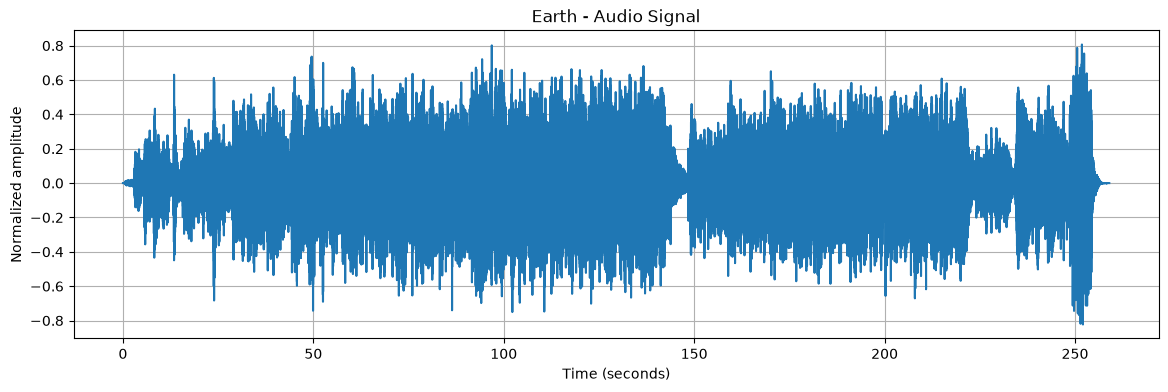

In [10]:
# Use fewer points only for plotting
target_points = 100_000
step = max(1, len(x) // target_points)

plt.figure(figsize=(14, 4))
plt.plot(t[::step], x[::step])

plt.xlabel("Time (seconds)")
plt.ylabel("Normalized amplitude")
plt.title("Earth - Audio Signal")
plt.grid()

plt.show()

### 2.3 Local Mean-Square Signal Level

The raw audio function \(x(t)\) changes too rapidly to reveal the slower rhythmic structure directly.

A simple way to describe the local strength of the signal is to square its amplitude:

$$
x^2(t).
$$

Squaring has two useful effects:

- positive and negative amplitudes no longer cancel each other;
- larger amplitudes contribute more strongly.

The signal is then divided into short time intervals. For each interval, the average squared amplitude is calculated:

$$
E_i =
\frac{1}{N}
\sum_{k=0}^{N-1} x^2_{iN+k},
$$

where \(N\) is the number of audio samples in one time window.

This produces a new, much slower function \(E(t)\), which represents the local mean-square signal level over time.

In [11]:
# Duration of one analysis window
window_seconds = 0.05

# Number of audio samples in one window
window_size = int(window_seconds * sample_rate)

# Keep only the part that fits into complete windows
usable_samples = (len(x) // window_size) * window_size
x_trimmed = x[:usable_samples]

# Split the signal into equal time windows
windows = x_trimmed.reshape(-1, window_size)

# Mean squared amplitude in every window
local_energy = np.mean(windows ** 2, axis=1)

# Time position of every energy value
energy_time = np.arange(len(local_energy)) * window_seconds

print("Window duration:", window_seconds, "seconds")
print("Samples per window:", window_size)
print("Number of energy values:", len(local_energy))

Window duration: 0.05 seconds
Samples per window: 2400
Number of energy values: 5180


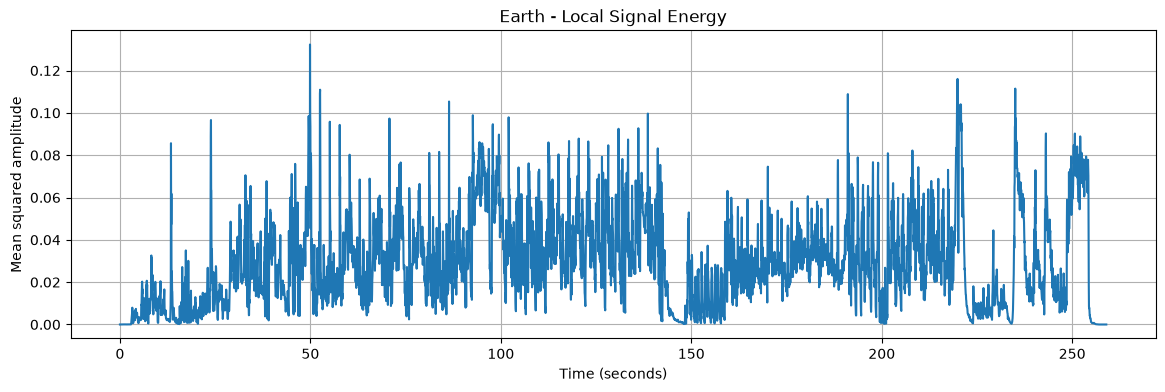

In [12]:
plt.figure(figsize=(14, 4))
plt.plot(energy_time, local_energy)

plt.xlabel("Time (seconds)")
plt.ylabel("Mean squared amplitude")
plt.title("Earth - Local Signal Energy")
plt.grid()

plt.show()

### 2.4 Rate of Change

The local mean-square signal level changes over time. To measure how quickly it changes, a numerical approximation of the first derivative can be used.

For consecutive values separated by a time interval \(\Delta t\):

$$
E'(t) \approx \frac{E(t + \Delta t) - E(t)}{\Delta t}.
$$

Large positive values indicate a rapid increase in signal level, while large negative values indicate a rapid decrease.

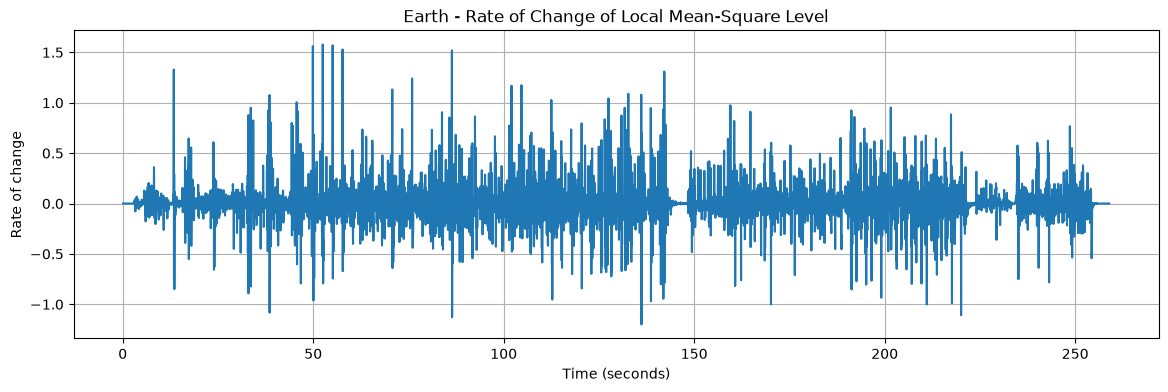

In [13]:
# Numerical approximation of the first derivative
energy_change = np.diff(local_energy) / window_seconds

# Corresponding time values
change_time = energy_time[1:]

plt.figure(figsize=(14, 4))
plt.plot(change_time, energy_change)

plt.xlabel("Time (seconds)")
plt.ylabel("Rate of change")
plt.title("Earth - Rate of Change of Local Mean-Square Level")
plt.grid()

plt.show()

#### Observation

The first derivative highlights rapid changes in the local signal level, producing clear positive and negative peaks.

However, the result contains many short-term changes and does not directly reveal the slower periodic pattern observed during manual editing.

This suggests that rate of change may be useful for detecting strong musical events(usefull for part III - Fire, but not for part IV - Earth), but a different method is needed to investigate repeated timing patterns.

### 2.5 Searching for Periodicity

A repeated rhythmic structure should produce similar signal patterns at regular time intervals.

To test this, the local signal-level function can be compared with a shifted copy of itself.

For two vectors, similarity can be measured using the dot product. If the signal resembles itself after a time shift \(\tau\), the similarity should increase for that shift.

The goal is to test different time shifts and determine whether some intervals produce consistently higher similarity.

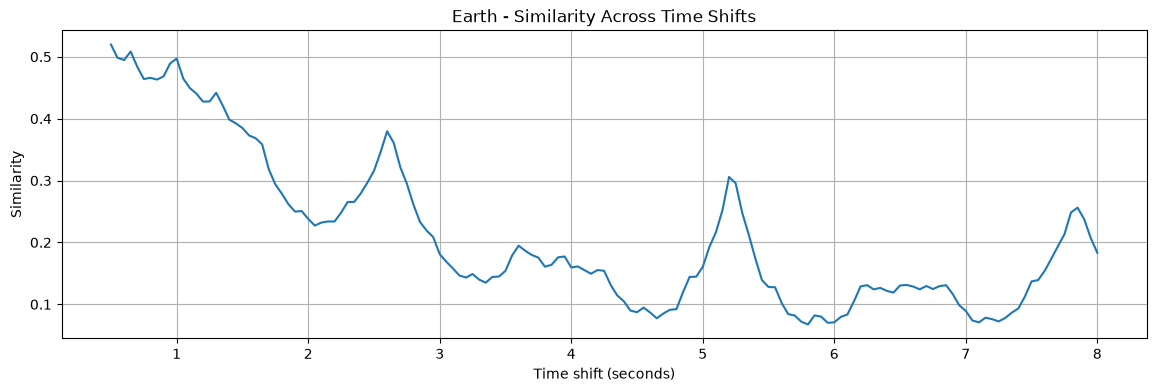

In [15]:
# Remove the average level so that we compare variations around the mean
energy_centered = local_energy - np.mean(local_energy)

# Test time shifts from 0.5 to 8 seconds
min_lag_seconds = 0.5
max_lag_seconds = 8.0

min_lag = int(min_lag_seconds / window_seconds)
max_lag = int(max_lag_seconds / window_seconds)

lags = np.arange(min_lag, max_lag + 1)
similarities = []

for lag in lags:
    a = energy_centered[:-lag]
    b = energy_centered[lag:]

    similarity = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    similarities.append(similarity)

lag_times = lags * window_seconds
similarities = np.array(similarities)

plt.figure(figsize=(14, 4))
plt.plot(lag_times, similarities)

plt.xlabel("Time shift (seconds)")
plt.ylabel("Similarity")
plt.title("Earth - Similarity Across Time Shifts")
plt.grid()

plt.show()

#### Observation

The similarity curve shows a strong expected value for very small time shifts, since nearby parts of the signal naturally resemble each other.

More importantly, the graph contains clear local maxima around approximately **2.6 s**, **5.2 s**, and **7.8 s**. These values are close to multiples of a common interval.

This suggests that the audio signal may contain a repeated temporal structure with an underlying period of approximately **2.6 seconds**.

This pattern is consistent with the manually observed editing rhythm and may be useful for identifying natural candidate cut points.